# Heart curve gallery: 2D, 3D and animation

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 06b · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/06b_Heart_Curve_Gallery_2D_3D_and_Animation.ipynb)

An optional companion to notebook 06, *Drawing heart curves with Python*.

A short gallery for students who have finished the heart-curve case study and want to try three more Matplotlib tools: filled 2D curves, a 3D surface built from an implicit equation, and an animation saved as a GIF. Run the cells from top to bottom. Only NumPy, Matplotlib and Pillow (installed with Matplotlib) are needed.

**Try it:** after each cell, change one number (colour, scale, number of frames) and predict the effect before re-running.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Optional · Part 2, Collections and data |
| **Time** | about 10 min |
| **Before this** | Notebook 06. |
| **Essential** | All four short sections. |
| **Optional on a first reading** | — |
| **Next** | 07, Engineering design optimization. |

**You have understood this notebook if you can, without looking back:**

1. Fill a closed curve with colour.
2. Explain how setting points to NaN cuts a 3D surface to a shape.
3. Explain what the `update(frame)` function does in `FuncAnimation`, and change the number of frames.

**Not expected of you:** Anything beyond trying the code and changing parameters.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

In [1]:
# Import NumPy for arrays of angles and coordinates.
import numpy as np
# Import Matplotlib's pyplot interface for drawing figures.
import matplotlib.pyplot as plt
# Import the animation driver and the writer that saves frames as a GIF.
from matplotlib.animation import FuncAnimation, PillowWriter

## 1. A filled parametric heart

The classic curve $x=16\sin^3 t$, $y=13\cos t-5\cos 2t-2\cos 3t-\cos 4t$ is sampled at 1200 values of $t\in[0,2\pi]$. `plt.fill` shades the closed outline; `plt.axis('equal')` keeps the shape undistorted.

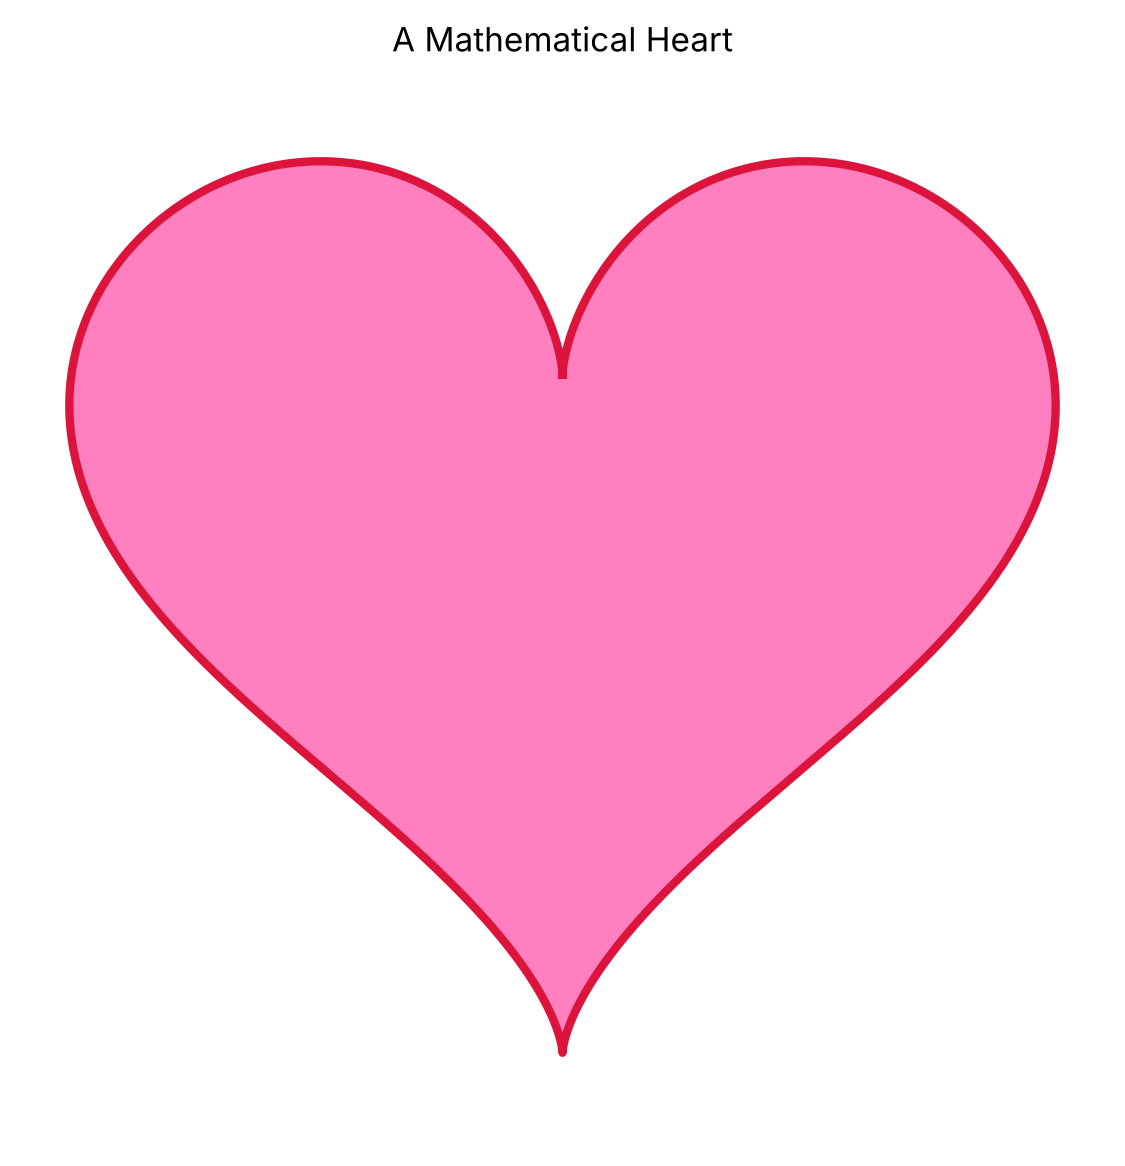

In [2]:
# ============================================================
# Common 2D parametric heart curve
# ============================================================
t = np.linspace(0, 2*np.pi, 1200)

# Horizontal coordinate: 16 sin³(t) gives the heart's width of 32 units.
x = 16 * np.sin(t)**3
# Vertical coordinate: the sum of cosines shapes the two lobes and the bottom point.
y = (
    13 * np.cos(t)
    - 5 * np.cos(2*t)
    - 2 * np.cos(3*t)
    - np.cos(4*t)
)

# ============================================================
# 1) Filled colorful heart
# ============================================================
plt.figure(figsize=(7, 7))
# Draw the outline as a thick red line through all 1200 points.
plt.plot(x, y, color="crimson", linewidth=3)
# Shade the closed outline; alpha < 1 makes the fill slightly transparent.
plt.fill(x, y, color="hotpink", alpha=0.85)
# Add a title above the figure.
plt.title("A Mathematical Heart")
# Use equal scaling on both axes so the heart is not stretched.
plt.axis("equal")
# Hide the axes, ticks and frame: this figure is a picture, not a graph.
plt.axis("off")
# Display the finished figure.
plt.show()


## 2. A 3D surface from an implicit equation

Points with $F(x,y)=(x^2+y^2-1)^3-x^2y^3\le 0$ lie inside the heart. Outside, the height is set to `NaN` so Matplotlib leaves a gap. Inside, the height grows with $\sqrt{-F}$, normalised to a maximum of 0.55; the lower surface is a scaled mirror image. This is a decorative surface, not a physical model.

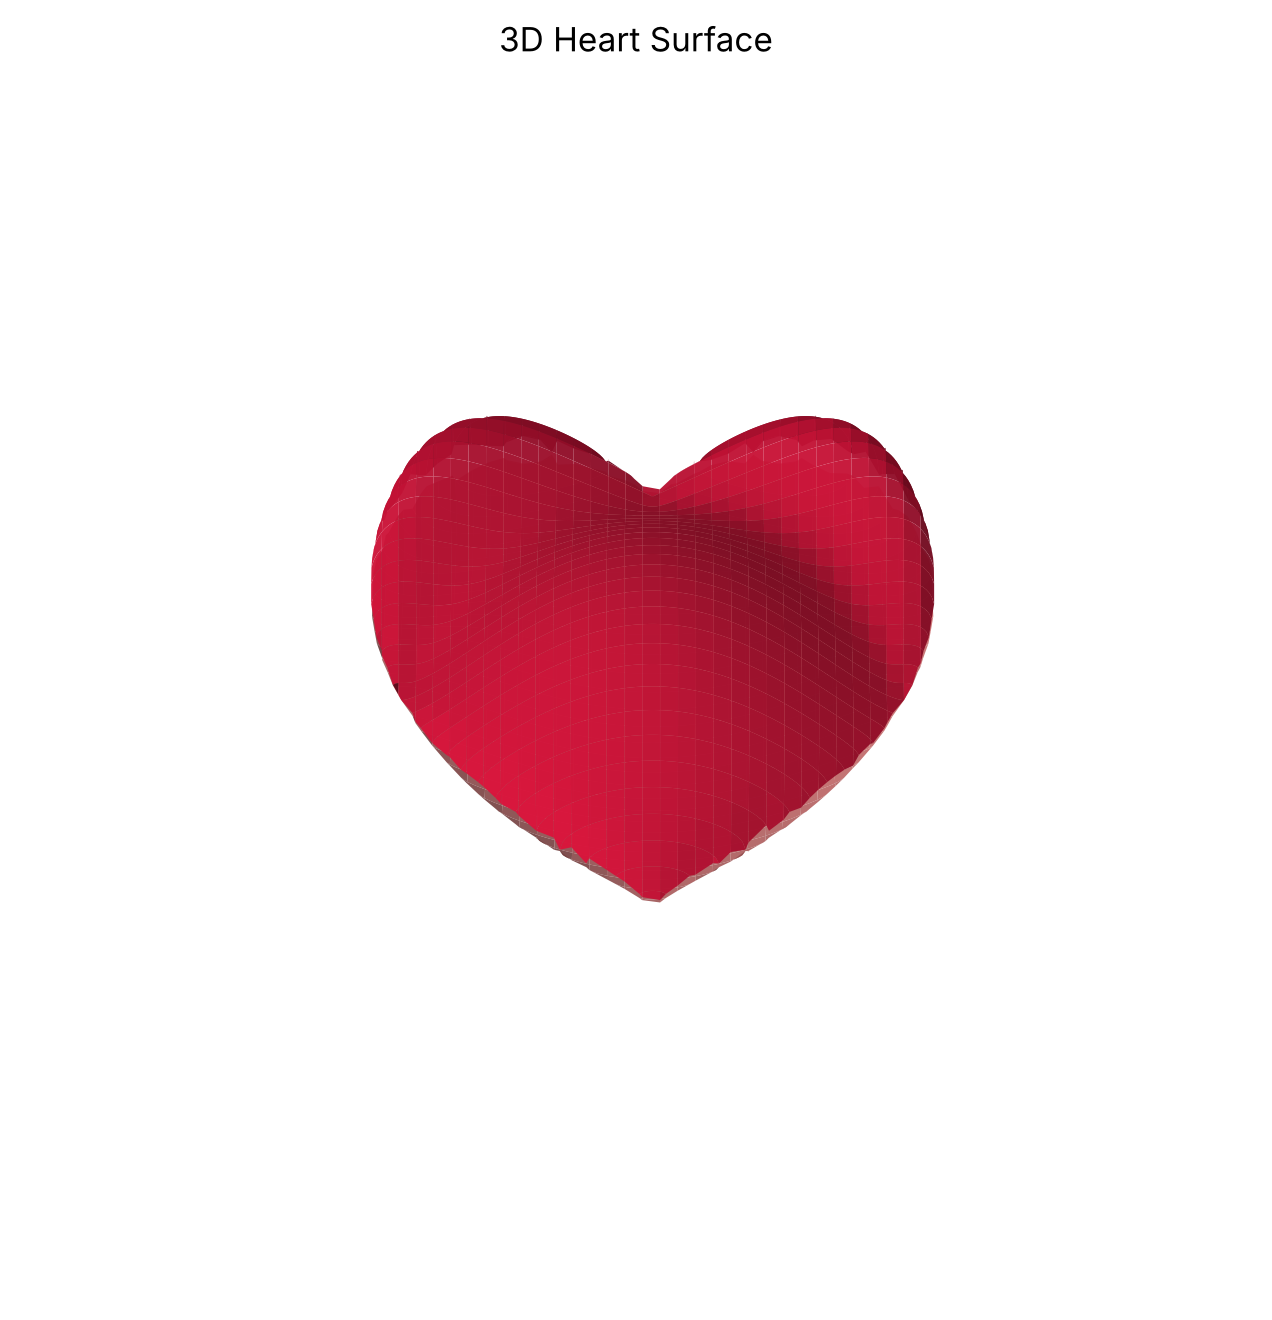

In [3]:

# ============================================================
# 2) 3D heart surface
# ============================================================
x3 = np.linspace(-1.5, 1.5, 260)
# Sample y slightly higher (to 1.6) because the implicit heart's lobes reach above y = 1.5.
y3 = np.linspace(-1.5, 1.6, 260)

# Build 2D grids: X3[i, j] and Y3[i, j] are the coordinates of grid point (i, j).
X3, Y3 = np.meshgrid(x3, y3)

# Classic implicit heart:
# (x^2 + y^2 - 1)^3 - x^2*y^3 = 0
F3 = (X3**2 + Y3**2 - 1)**3 - X3**2 * Y3**3

# Boolean mask: True for grid points inside or on the heart (F ≤ 0).
inside = F3 <= 0

# Start with NaN everywhere; Matplotlib leaves NaN points out of the surface.
Z3 = np.full_like(F3, np.nan, dtype=float)
# Inside the heart -F is positive; clip negative values to 0 so sqrt never sees them.
depth = np.maximum(-F3, 0)
# Height grows with sqrt(-F), scaled so the tallest point is 0.55.
Z3[inside] = 0.55 * np.sqrt(depth[inside] / np.max(depth[inside]))

# Create a square figure window.
fig = plt.figure(figsize=(8, 8))
# Add one set of 3D axes to the figure.
ax = fig.add_subplot(111, projection="3d")

# Draw the upper surface in crimson; linewidth=0 hides the mesh lines.
ax.plot_surface(
    X3, Y3, Z3,
    color="crimson",
    linewidth=0,
    antialiased=True,
    alpha=0.96,
)

# Draw a flatter mirror image below (height × -0.55) to give the heart thickness.
ax.plot_surface(
    X3, Y3, -0.55*Z3,
    color="lightcoral",
    linewidth=0,
    antialiased=True,
    alpha=0.9,
)

# Squash the vertical box so the heart looks like a flat cushion.
ax.set_box_aspect((1, 1, 0.38))
# Choose the camera elevation and azimuth (degrees) for viewing.
ax.view_init(elev=58, azim=-90)
# Hide the 3D axes and panes.
ax.set_axis_off()
# Add a title.
ax.set_title("3D Heart Surface")

# Display the 3D figure.
plt.show()


## 3. A beating heart animation

`FuncAnimation` calls `update(frame)` 30 times. Each frame rescales the outline by $1+0.08\sin(2\pi\,\text{frame}/30)$ and replaces the previous filled patch. The animation is written to `beating_heart.gif` in the notebook's folder; `plt.show()` then displays only a static frame.

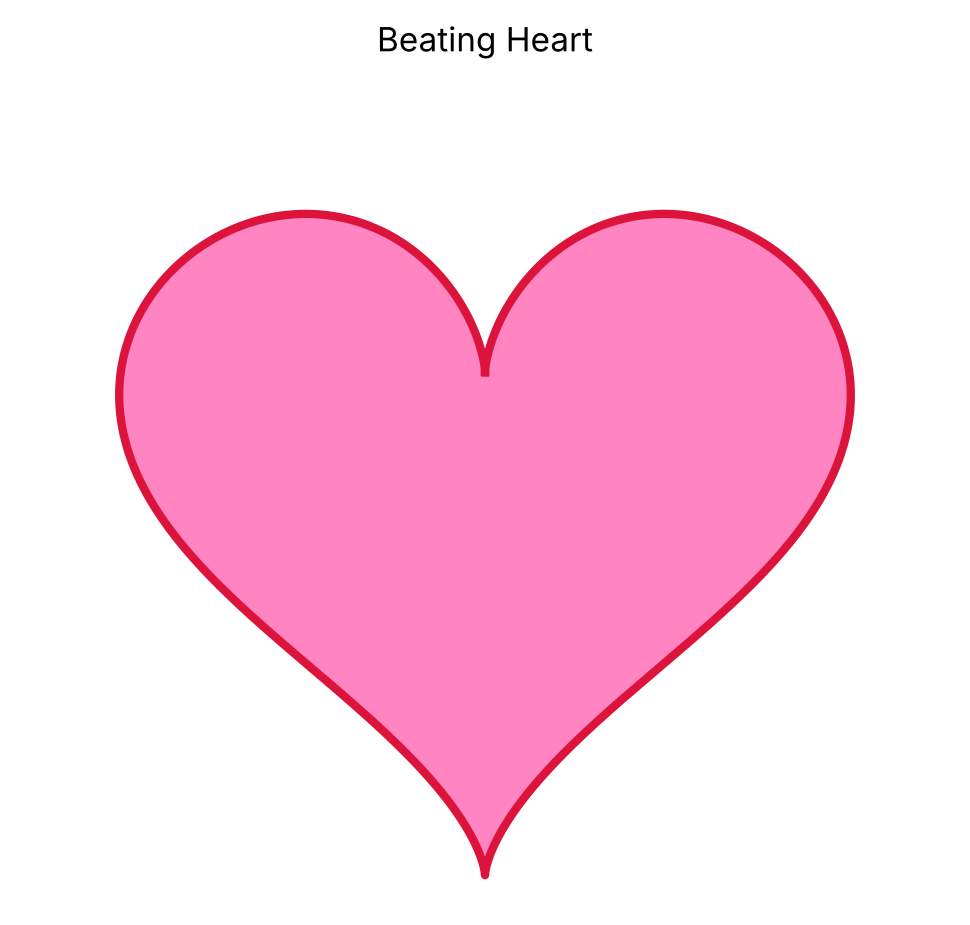

In [4]:

# ============================================================
# 3) Animated beating heart
# ============================================================
fig = plt.figure(figsize=(6, 6))
# Get the current axes of the new figure.
ax = plt.gca()

# Use equal scaling so the heart keeps its shape as it beats.
ax.set_aspect("equal")
# Fix the x-range so the view does not jump between frames.
ax.set_xlim(-20, 20)
# Fix the y-range for the same reason.
ax.set_ylim(-18, 18)
# Hide the axes.
ax.axis("off")
# Add a title.
ax.set_title("Beating Heart")

# Create an empty line now; update() fills in its data on every frame (note the comma: plot returns a list).
line, = ax.plot([], [], color="crimson", linewidth=3)
# A one-item list that remembers the current fill patch so it can be removed later.
fill_holder = []

# Define the function FuncAnimation calls once per frame, with frame = 0, 1, ..., 29.
def update(frame):
    # Periodic expansion/contraction
    scale = 1.0 + 0.08 * np.sin(2*np.pi * frame / 30)

    # Scale every x-coordinate of the outline for this frame.
    xb = scale * x
    # Scale every y-coordinate by the same factor.
    yb = scale * y

    # Move the outline line to the scaled coordinates.
    line.set_data(xb, yb)

    # If a fill from the previous frame exists ...
    if fill_holder:
        # ... remove it from the axes ...
        fill_holder[0].remove()
        # ... and empty the list, ready for the new patch.
        fill_holder.clear()

    # Draw this frame's filled heart; ax.fill returns a list, so [0] takes the single patch.
    patch = ax.fill(
        xb, yb,
        color="hotpink",
        alpha=0.82
    )[0]

    # Remember the new patch so the next frame can remove it.
    fill_holder.append(patch)

    # Return the changed artists, as FuncAnimation expects.
    return [line, patch]

# Build the animation: 30 frames, 55 ms apart on screen.
animation = FuncAnimation(
    fig,
    update,
    frames=30,
    interval=55,
    blit=False,
)

# Write all frames to a GIF file at 18 frames per second (needs Pillow, installed with Matplotlib).
animation.save(
    "beating_heart.gif",
    writer=PillowWriter(fps=18)
)

# Show the figure; in a notebook this displays one static frame.
plt.show()


To see the animation inside the notebook, display the saved GIF file:

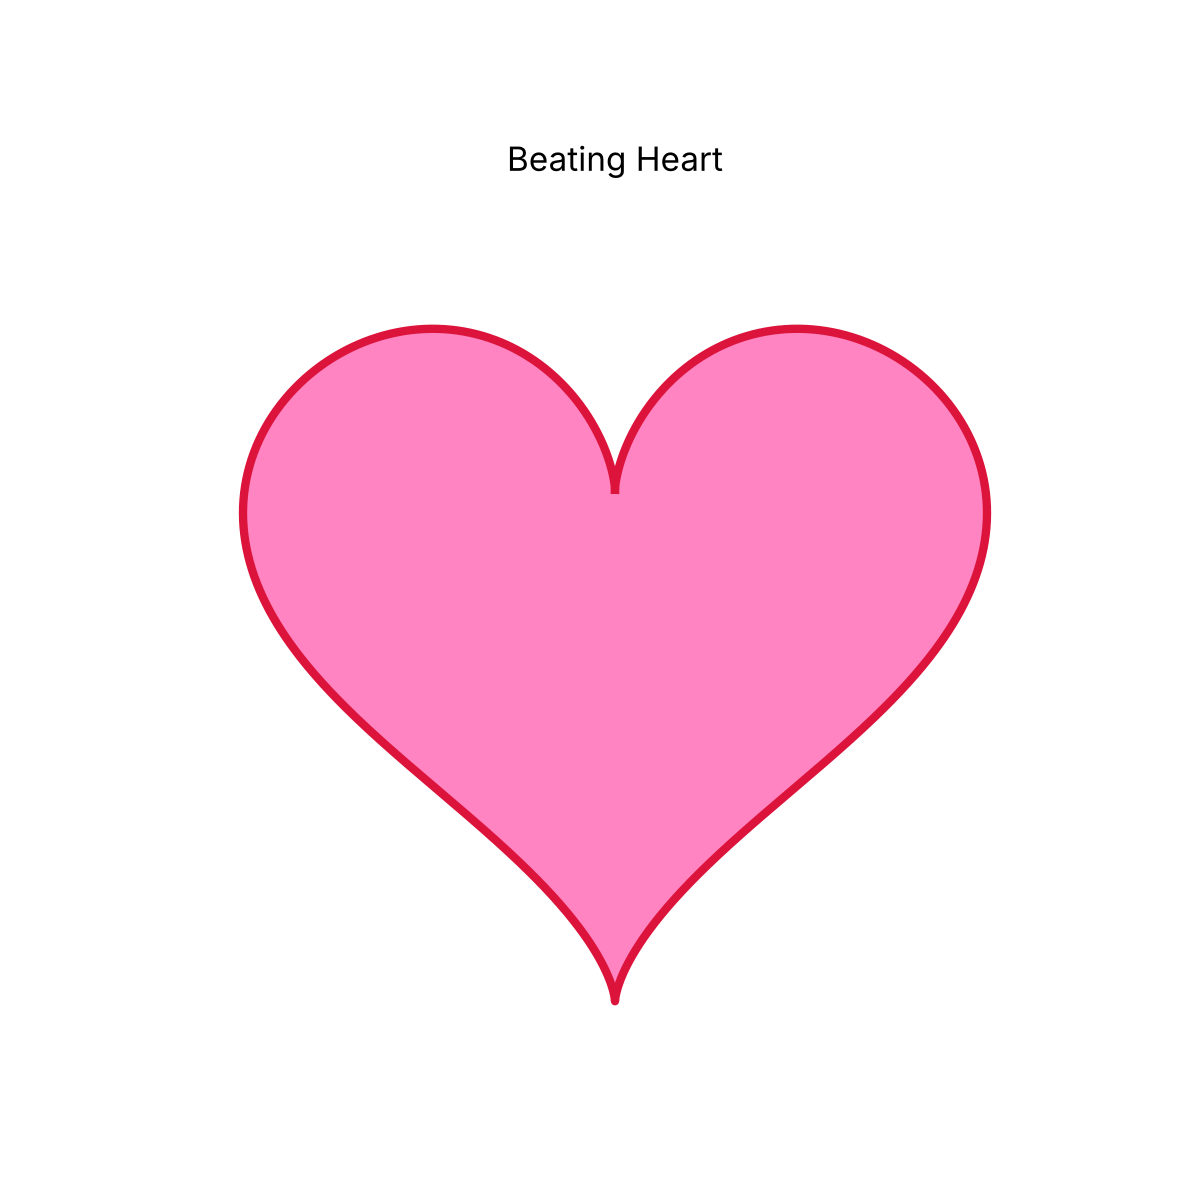

In [5]:
# Import tools that display images inside the notebook.
from IPython.display import Image, display
# Read the saved GIF as bytes and display it, so the animation plays in the notebook.
display(Image(open('beating_heart.gif','rb').read()))

## 4. Add text to a figure

`plt.text` places a label at data coordinates $(0,0)$, centred both ways.

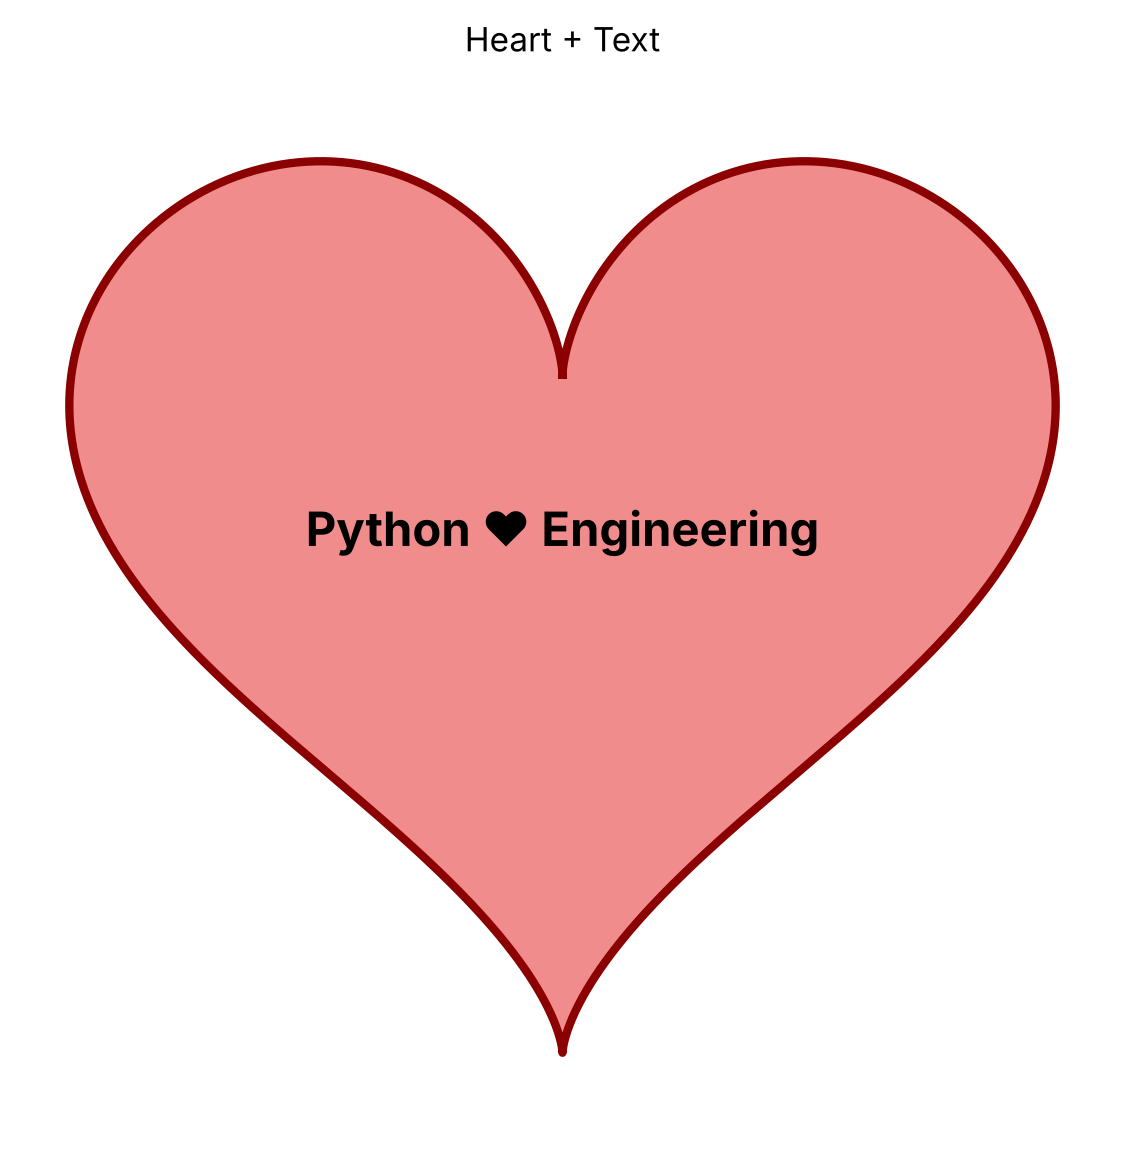

In [6]:
# ============================================================
# 4) Heart with text inside
# ============================================================
message = "Python ♥ Engineering"

# Create a new square figure.
plt.figure(figsize=(7, 7))

# Draw the outline (x and y come from Section 1).
plt.plot(x, y, color="darkred", linewidth=3)
# Fill the outline with a light colour so the text stays readable.
plt.fill(x, y, color="lightcoral", alpha=0.9)

# Write the message at (0, 0), centred horizontally and vertically.
plt.text(
    0,
    0,
    message,
    ha="center",
    va="center",
    fontsize=17,
    weight="bold",
)

# Keep equal axis scaling.
plt.axis("equal")
# Hide the axes.
plt.axis("off")
# Add a title.
plt.title("Heart + Text")

# Display the figure.
plt.show()


**Further practice.** Combine Section 3 with the cardioid or implicit hearts from the case study, or save a figure as SVG with `plt.savefig('heart.svg')` for a laser-cutter-style vector outline.